In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import struct
import time
import warnings
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "logistic-regression-baseline"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib", "threadpoolctl")}}
display(pd.Series(environment, name="Version"))

python           3.12.0
numpy             2.5.4
pandas            3.0.6
scikit-learn      1.9.1
joblib            1.6.0
threadpoolctl     3.7.0
Name: Version, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = images[train_indices].reshape(len(train_indices), -1).astype(np.float64) / 255.0
X_validation = images[validation_indices].reshape(len(validation_indices), -1).astype(np.float64) / 255.0
y_train = labels[train_indices]
y_validation = labels[validation_indices]
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "images": [len(y_train), len(y_validation)], "features": [X_train.shape[1], X_validation.shape[1]]}))

,split,images,features
0,Training,48000,784
1,Validation,12000,784


In [3]:
parameters = {"C": 1.0, "l1_ratio": 0.0, "solver": "lbfgs", "max_iter": 1000, "tol": 1e-4, "random_state": SEED}
model = LogisticRegression(**parameters)
start = time.perf_counter()
with threadpool_limits(limits=4), warnings.catch_warnings(record=True) as recorded_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    model.fit(X_train, y_train)
fit_seconds = time.perf_counter() - start
convergence_warnings = [str(w.message) for w in recorded_warnings if issubclass(w.category, ConvergenceWarning)]
if convergence_warnings:
    raise RuntimeError("Optimizer did not converge: " + "; ".join(convergence_warnings))
for warning in recorded_warnings:
    warnings.warn(str(warning.message), warning.category)
display(pd.Series({"fit_seconds": round(fit_seconds, 2), "iterations": int(model.n_iter_.max()), "convergence_warnings": len(convergence_warnings), **parameters}, name="Training run"))

fit_seconds              21.84
iterations                 603
convergence_warnings         0
C                          1.0
l1_ratio                   0.0
solver                   lbfgs
max_iter                  1000
tol                     0.0001
random_state                42
Name: Training run, dtype: object

In [4]:
with threadpool_limits(limits=4):
    train_probabilities = model.predict_proba(X_train)
    validation_probabilities = model.predict_proba(X_validation)
train_predictions = model.classes_[train_probabilities.argmax(axis=1)]
validation_predictions = model.classes_[validation_probabilities.argmax(axis=1)]
assert np.isfinite(validation_probabilities).all()
assert np.allclose(validation_probabilities.sum(axis=1), 1)
metrics = []
for name, target, predictions, probabilities in [
    ("Training", y_train, train_predictions, train_probabilities),
    ("Validation", y_validation, validation_predictions, validation_probabilities),
]:
    metrics.append({"split": name, "accuracy": accuracy_score(target, predictions),
                    "macro_f1": f1_score(target, predictions, average="macro"),
                    "log_loss": log_loss(target, probabilities, labels=model.classes_)})
metrics_table = pd.DataFrame(metrics).set_index("split")
display(metrics_table.round(4))
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_accuracy = accuracy_score(y_validation, dummy.predict(X_validation))
accuracy_gap = metrics_table.loc["Training", "accuracy"] - metrics_table.loc["Validation", "accuracy"]
print(f"Most-frequent-class validation accuracy: {dummy_accuracy:.2%}")
print(f"Training minus validation accuracy: {100 * accuracy_gap:.2f} percentage points")

,accuracy,macro_f1,log_loss
split,,,
Training,0.8843,0.8836,0.3294
Validation,0.8532,0.8523,0.4363


Most-frequent-class validation accuracy: 10.00%
Training minus validation accuracy: 3.11 percentage points


,precision,recall,f1-score,support
T-shirt/top,0.7880,0.7992,0.7935,1200
Trouser,0.9741,0.9733,0.9737,1200
Pullover,0.7519,0.7575,0.7547,1200
Dress,0.8662,0.8792,0.8726,1200
Coat,0.7598,0.7908,0.7750,1200
Sandal,0.9439,0.9258,0.9348,1200
Shirt,0.6478,0.5900,0.6175,1200
Sneaker,0.9071,0.9275,0.9172,1200
Bag,0.9352,0.9508,0.9430,1200
Ankle boot,0.9446,0.9375,0.9410,1200


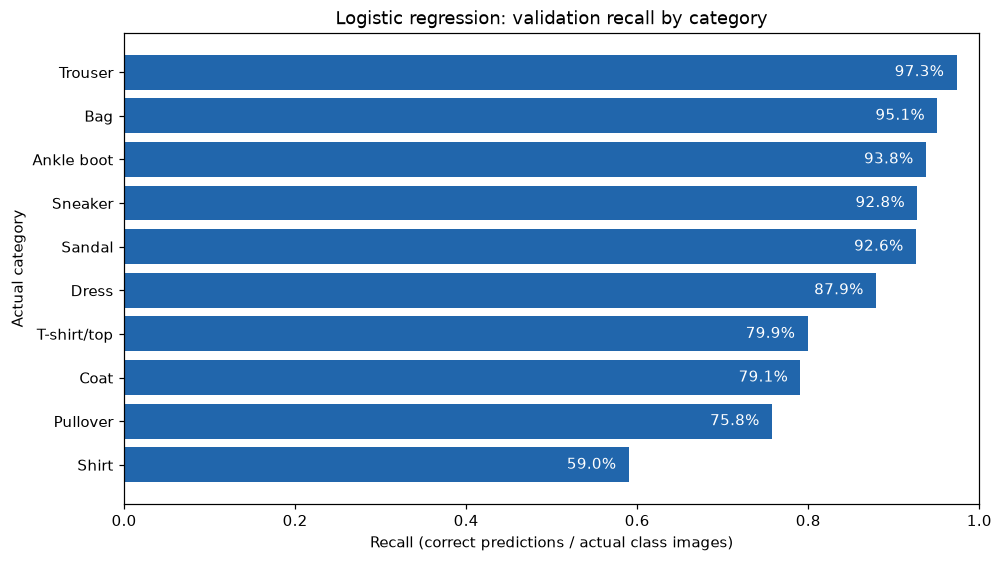

In [5]:
report = classification_report(y_validation, validation_predictions, labels=np.arange(10), target_names=CLASS_NAMES.tolist(), output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ordered = per_class.sort_values("recall")
ax.barh(ordered.index, ordered.recall, color="#2166ac")
ax.set(xlim=(0, 1), xlabel="Recall (correct predictions / actual class images)", ylabel="Actual category", title="Logistic regression: validation recall by category")
for position, value in enumerate(ordered.recall):
    ax.text(max(value - 0.015, 0.01), position, f"{value:.1%}", va="center", ha="right", color="white")
fig.savefig(RESULTS / "validation-recall.png", bbox_inches="tight")
plt.show()

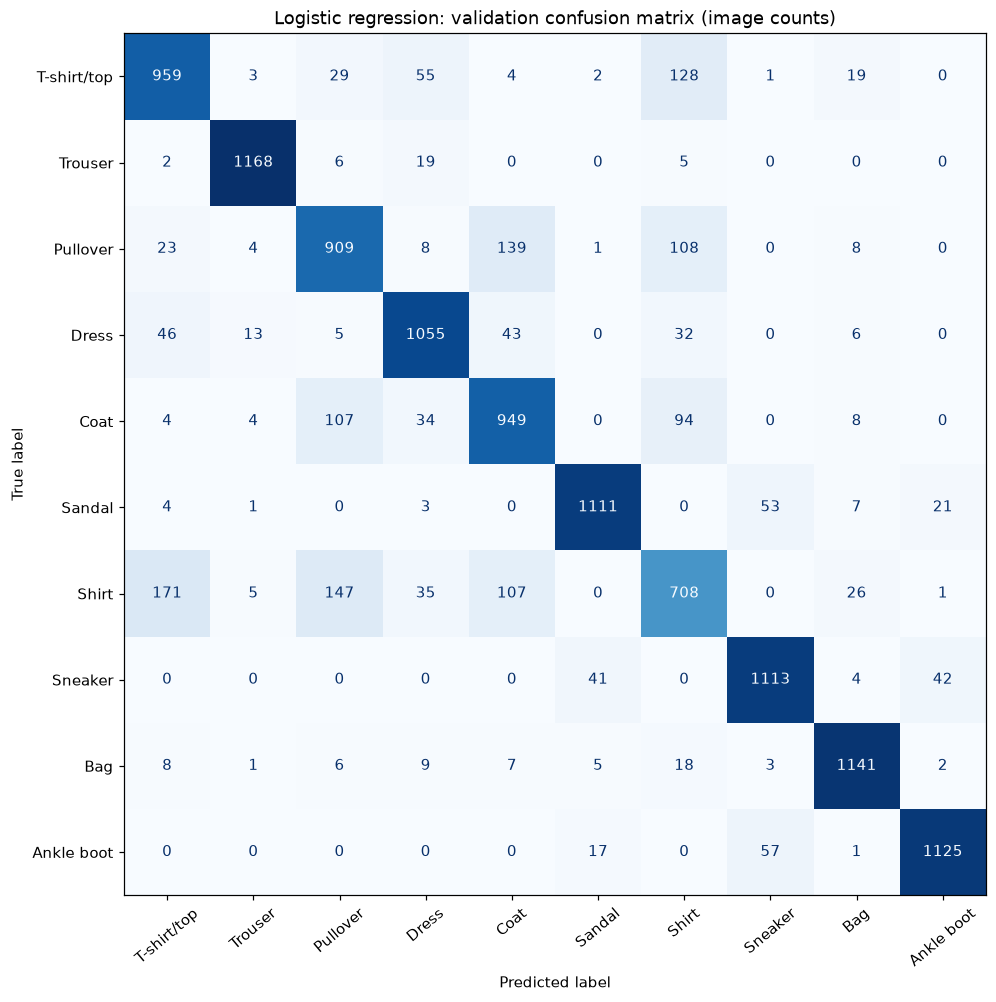

,actual,predicted,images,share_of_actual_class
0,Shirt,T-shirt/top,171,0.1425
1,Shirt,Pullover,147,0.1225
2,Pullover,Coat,139,0.1158
3,T-shirt/top,Shirt,128,0.1067
4,Pullover,Shirt,108,0.0900
5,Coat,Pullover,107,0.0892
6,Shirt,Coat,107,0.0892
7,Coat,Shirt,94,0.0783
8,Ankle boot,Sneaker,57,0.0475
9,T-shirt/top,Dress,55,0.0458


In [6]:
matrix = confusion_matrix(y_validation, validation_predictions, labels=np.arange(10))
assert matrix.sum() == len(y_validation)
assert np.isclose(np.trace(matrix) / matrix.sum(), metrics_table.loc["Validation", "accuracy"])
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=40, colorbar=False)
ax.set_title("Logistic regression: validation confusion matrix (image counts)")
fig.savefig(RESULTS / "validation-confusion-matrix.png", bbox_inches="tight")
plt.show()
confusions = pd.DataFrame([
    {"actual": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "images": int(matrix[i,j]), "share_of_actual_class": float(matrix[i,j] / matrix[i].sum())}
    for i in range(10) for j in range(10) if i != j and matrix[i,j] > 0
]).sort_values("images", ascending=False).reset_index(drop=True)
display(confusions.head(10).round(4))

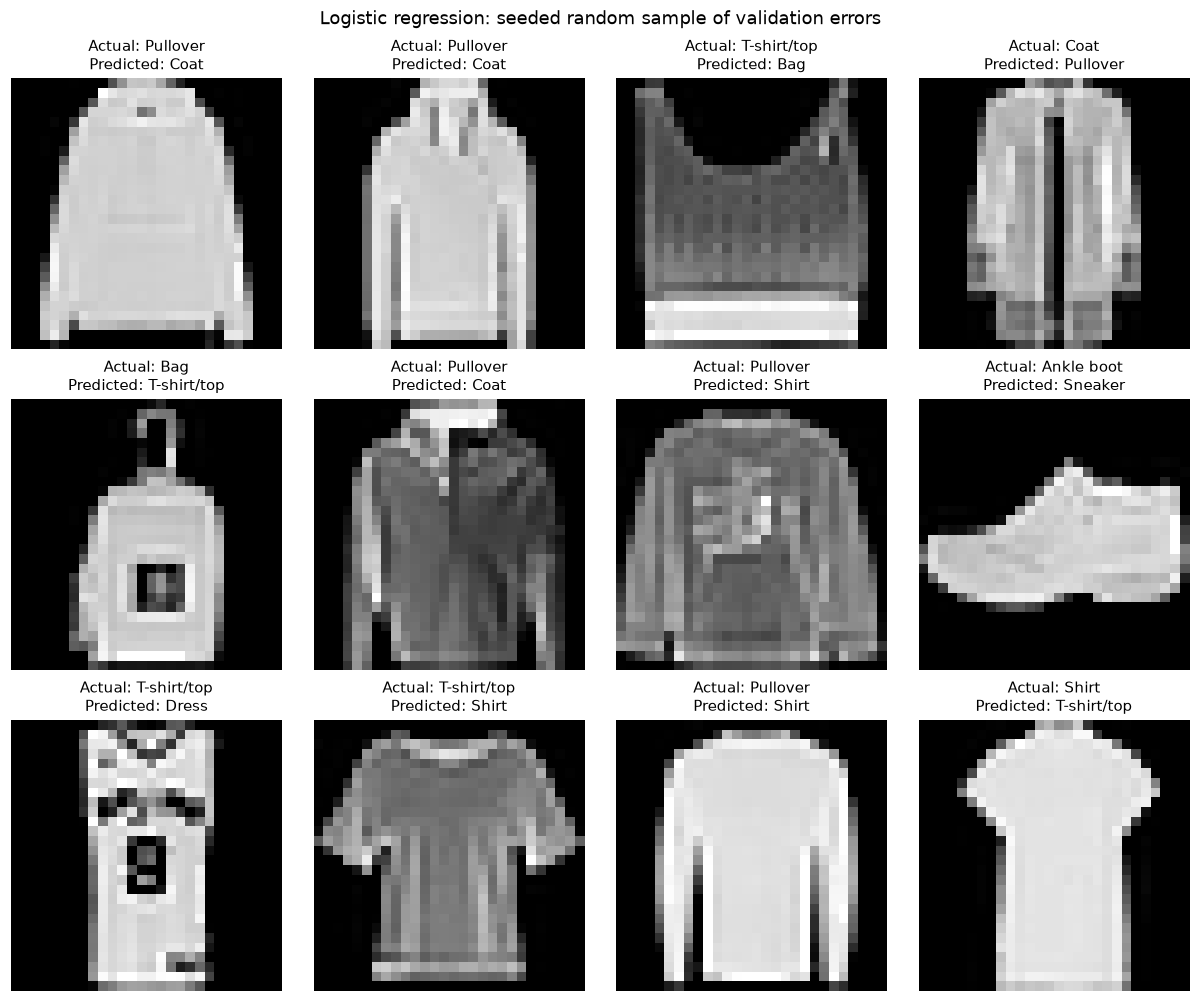

In [7]:
error_positions = np.flatnonzero(validation_predictions != y_validation)
rng = np.random.default_rng(SEED)
selected = rng.choice(error_positions, size=min(12, len(error_positions)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(11, 9), layout="constrained")
for ax in axes.ravel():
    ax.axis("off")
for ax, position in zip(axes.ravel(), selected):
    ax.imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Actual: {CLASS_NAMES[y_validation[position]]}\nPredicted: {CLASS_NAMES[validation_predictions[position]]}", fontsize=10)
fig.suptitle("Logistic regression: seeded random sample of validation errors")
fig.savefig(RESULTS / "validation-errors.png", bbox_inches="tight")
plt.show()

In [8]:
metrics_table.to_csv(RESULTS / "metrics.csv")
per_class.to_csv(RESULTS / "validation-classification-report.csv")
confusions.to_csv(RESULTS / "validation-confusions.csv", index=False)
pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RESULTS / "validation-confusion-matrix.csv")
pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": validation_predictions, "predicted_probability": validation_probabilities.max(axis=1)}).to_csv(RESULTS / "validation-predictions.csv", index=False)
model_path = RESULTS / "model.joblib"
joblib.dump(model, model_path)
restored = joblib.load(model_path)
with threadpool_limits(limits=4):
    np.testing.assert_array_equal(restored.predict(X_validation), validation_predictions)
run_metadata = {
    "model": "multinomial_logistic_regression", "regularization": "L2", "parameters": parameters,
    "environment": environment, "fit_seconds": fit_seconds, "iterations": int(model.n_iter_.max()),
    "convergence_warnings": convergence_warnings, "split_sha256": split_sha256,
    "source_files": training_files, "training_count": len(y_train), "validation_count": len(y_validation),
    "preprocessing": {"pixels_divisor": 255.0, "dtype": "float64", "flatten_order": "C", "features": 784},
    "class_names": CLASS_NAMES.tolist(), "metrics": metrics,
    "dummy_validation_accuracy": dummy_accuracy, "accuracy_gap": accuracy_gap,
    "test_evaluated": False, "hyperparameter_search": False,
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
}
(RESULTS / "run-metadata.json").write_text(json.dumps(run_metadata, indent=2) + "\n")
print("Saved results/logistic-regression-baseline artifacts")
print("Reloaded model reproduces all validation predictions")

Saved results/logistic-regression-baseline artifacts
Reloaded model reproduces all validation predictions
